In [1]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix

**MEAN**

In [2]:
rng = np.random.default_rng(42)

K = 5
N = 2000

weights = np.array([0.20, 0.20, 0.20, 0.20, 0.20])

means_0 = np.array([
    [-4.0, -3.0],
    [-2.0,  2.0],
    [ 0.0, -1.0],
    [ 2.0,  3.0],
    [ 4.0, -2.0]
])

means_1 = np.array([
    [-4.0,  3.0],
    [-2.0, -2.0],
    [ 0.0,  4.0],
    [ 2.0, -3.0],
    [ 4.0,  2.0]
])

**MATRIX FOR ALL COVARIANCES**

In [3]:
covariance_types = {
    "Isotropic": [
        1.0 * np.eye(2),
        0.8 * np.eye(2),
        1.2 * np.eye(2),
        0.6 * np.eye(2),
        1.5 * np.eye(2)
    ],

    "Diagonal": [
        np.array([[1.5, 0.0],
                  [0.0, 0.4]]),

        np.array([[0.5, 0.0],
                  [0.0, 1.5]]),

        np.array([[1.2, 0.0],
                  [0.0, 0.6]]),

        np.array([[0.8, 0.0],
                  [0.0, 1.8]]),

        np.array([[2.0, 0.0],
                  [0.0, 0.7]])
    ],

    "Full": [
        np.array([[1.5, 0.8],
                  [0.8, 1.0]]),

        np.array([[1.2, -0.6],
                  [-0.6, 1.0]]),

        np.array([[0.8, 0.3],
                  [0.3, 1.4]]),

        np.array([[1.5, -0.5],
                  [-0.5, 0.8]]),

        np.array([[1.0, 0.6],
                  [0.6, 1.5]])
    ]
}

**CALCULATING GAUSSIAN DENSITY AND GENERATING GMM DATA**

In [4]:

def gaussian_density(x, mean, covariance):
    d = len(mean)
    diff = x - mean

    det = np.linalg.det(covariance)
    inv = np.linalg.inv(covariance)

    exponent = -0.5 * diff.T @ inv @ diff

    coefficient = 1 / (
        (2 * np.pi) ** (d / 2) * np.sqrt(det)
    )

    return coefficient * np.exp(exponent)



def generate_gmm_data(means, covariances, n_samples):
    component_ids = rng.choice(
        K, size=n_samples, p=weights
    )

    X = np.zeros((n_samples, len(means[0])))

    standard_normal_values = box_muller(n_samples, rng)

    for i in range(K):
        indices = np.where(component_ids == i)[0]

        L = np.linalg.cholesky(covariances[i])

        X[indices] = (
            means[i] +
            standard_normal_values[indices] @ L.T
        )

    return X, component_ids

def box_muller(n_samples, rng):
    u1 = rng.random(n_samples)
    u2 = rng.random(n_samples)

    u1 = np.maximum(u1, np.finfo(float).tiny)

    r = np.sqrt(-2.0 * np.log(u1))
    theta = 2.0 * np.pi * u2

    z1 = r * np.cos(theta)
    z2 = r * np.sin(theta)

    return np.column_stack((z1, z2))



In [5]:
def plot_generated_data(X0, comp0, X1, comp1, title):
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    axes[0].scatter(
        X0[:, 0], X0[:, 1],
        c=comp0, cmap="viridis", s=12
    )
    axes[0].set_title("Class 0: Gaussian components")
    axes[0].set_xlabel("x1")
    axes[0].set_ylabel("x2")

    axes[1].scatter(
        X1[:, 0], X1[:, 1],
        c=comp1, cmap="viridis", s=12
    )
    axes[1].set_title("Class 1: Gaussian components")
    axes[1].set_xlabel("x1")
    axes[1].set_ylabel("x2")

    fig.suptitle(title)
    plt.tight_layout()
    plt.show()




**CALCULATE DISTORTION**

In [6]:
def calculate_distortion(X, model):
    distances = model.transform(X)
    squared_distances = distances ** 2

    cluster_ids = model.predict(X)

    distortion = squared_distances[
        np.arange(len(X)), cluster_ids
    ]

    return distortion

In [7]:
for covariance_name, covariances in covariance_types.items():

    print("\nCovariance type:", covariance_name)

    X0, comp0 = generate_gmm_data(
        means_0, covariances, N
    )

    X1, comp1 = generate_gmm_data(
        means_1, covariances, N
    )

    print("Class 0 data shape:", X0.shape)
    print("Class 1 data shape:", X1.shape)


Covariance type: Isotropic
Class 0 data shape: (2000, 2)
Class 1 data shape: (2000, 2)

Covariance type: Diagonal
Class 0 data shape: (2000, 2)
Class 1 data shape: (2000, 2)

Covariance type: Full
Class 0 data shape: (2000, 2)
Class 1 data shape: (2000, 2)


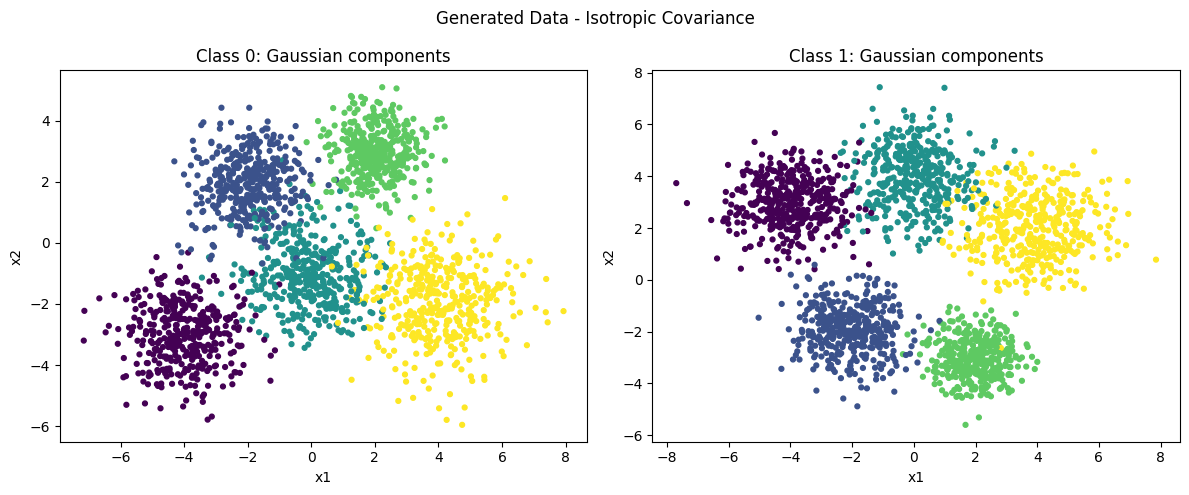

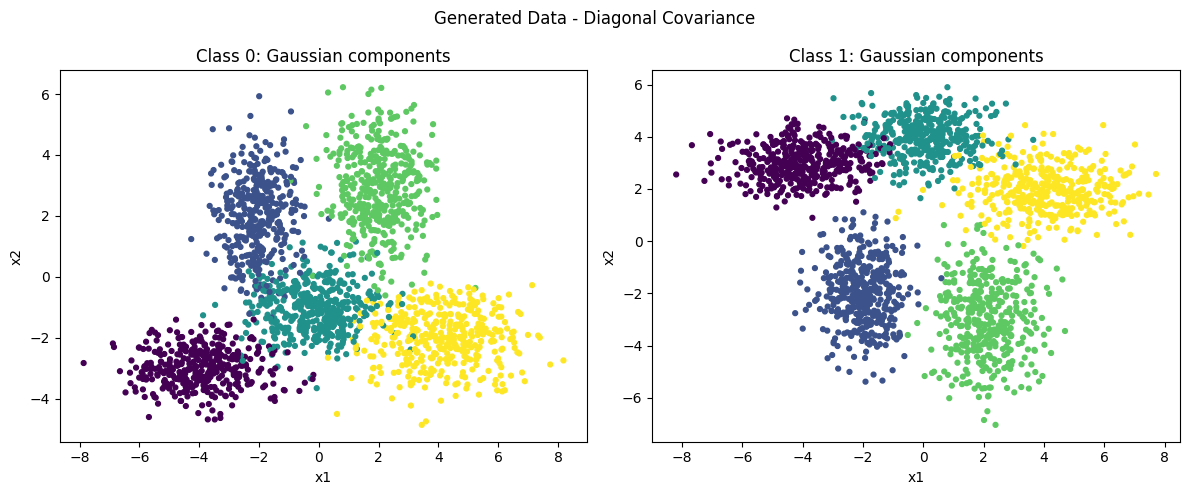

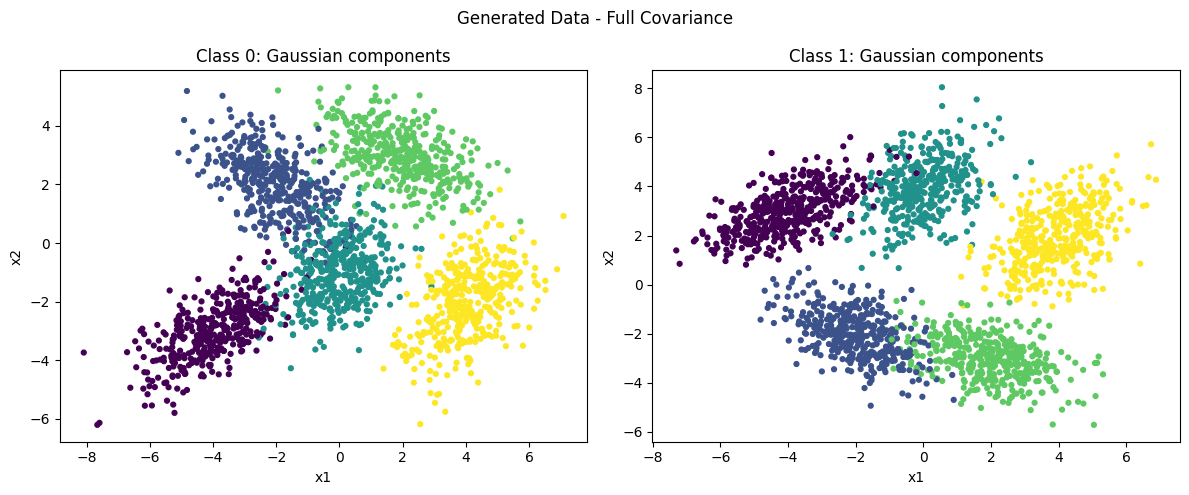

In [8]:
for covariance_name, covariances in covariance_types.items():

    X0, comp0 = generate_gmm_data(
        means_0, covariances, N
    )

    X1, comp1 = generate_gmm_data(
        means_1, covariances, N
    )

    plot_generated_data(
        X0, comp0, X1, comp1,
        f"Generated Data - {covariance_name} Covariance"
    )

**SPLITTING DATA**

In [9]:
for covariance_name, covariances in covariance_types.items():

    X0, _ = generate_gmm_data(means_0, covariances, N)
    X1, _ = generate_gmm_data(means_1, covariances, N)

    X0_train, X0_test = train_test_split(
        X0, test_size=0.20, random_state=42
    )

    X1_train, X1_test = train_test_split(
        X1, test_size=0.20, random_state=42
    )

    print("\nCovariance:", covariance_name)
    print("Class 0 training:", X0_train.shape)
    print("Class 0 testing:", X0_test.shape)
    print("Class 1 training:", X1_train.shape)
    print("Class 1 testing:", X1_test.shape)


Covariance: Isotropic
Class 0 training: (1600, 2)
Class 0 testing: (400, 2)
Class 1 training: (1600, 2)
Class 1 testing: (400, 2)

Covariance: Diagonal
Class 0 training: (1600, 2)
Class 0 testing: (400, 2)
Class 1 training: (1600, 2)
Class 1 testing: (400, 2)

Covariance: Full
Class 0 training: (1600, 2)
Class 0 testing: (400, 2)
Class 1 training: (1600, 2)
Class 1 testing: (400, 2)


**K MEANS CLUSTERING**

In [10]:
def kmeans(X, K, max_iters=100, tolerance=1e-4, random_state=42):

    rng = np.random.default_rng(random_state)

    # 1. Randomly initialize K centroids from the data points
    indices = rng.choice(len(X), size=K, replace=False)
    centroids = X[indices].copy()

    for iteration in range(max_iters):

        # 2. Calculate distances from every point to every centroid
        distances = np.linalg.norm(
            X[:, np.newaxis, :] - centroids[np.newaxis, :, :],
            axis=2
        )

        # 3. Assign each point to its nearest centroid
        labels = np.argmin(distances, axis=1)

        # 4. Calculate new centroids using cluster means
        new_centroids = np.zeros_like(centroids)

        for k in range(K):
            cluster_points = X[labels == k]

            if len(cluster_points) > 0:
                new_centroids[k] = np.mean(cluster_points, axis=0)
            else:
                # Reinitialize an empty cluster
                new_centroids[k] = X[rng.integers(len(X))]

        # 5. Check convergence
        movement = np.linalg.norm(new_centroids - centroids)

        centroids = new_centroids

        if movement < tolerance:
            break

    # Reassign points using the final centroids
    distances = np.linalg.norm(
        X[:, np.newaxis, :] - centroids[np.newaxis, :, :],
        axis=2
    )
    labels = np.argmin(distances, axis=1)

    return centroids, labels, iteration + 1


In [11]:

def plot_cluster_boundaries(X, centroids, title):
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 300),
        np.linspace(y_min, y_max, 300)
    )

    grid = np.c_[xx.ravel(), yy.ravel()]

    distances = np.linalg.norm(
        grid[:, np.newaxis, :] - centroids[np.newaxis, :, :],
        axis=2
    )

    regions = np.argmin(distances, axis=1).reshape(xx.shape)

    labels = np.argmin(
        np.linalg.norm(
            X[:, np.newaxis, :] - centroids[np.newaxis, :, :],
            axis=2
        ),
        axis=1
    )

    plt.figure(figsize=(9, 7))

    plt.contourf(
        xx, yy, regions,
        levels=np.arange(len(centroids) + 1) - 0.5,
        cmap="viridis",
        alpha=0.25
    )

    plt.contour(
        xx, yy, regions,
        levels=np.arange(len(centroids) - 1) + 0.5,
        colors="black",
        linewidths=1.5
    )

    plt.scatter(
        X[:, 0], X[:, 1],
        c=labels, cmap="viridis",
        s=12, alpha=0.7
    )

    plt.scatter(
        centroids[:, 0], centroids[:, 1],
        c="red", marker="X", s=200,
        edgecolors="black",
        label="Centroids"
    )

    plt.title(title)
    plt.xlabel("x1")
    plt.ylabel("x2")
    plt.legend()
    plt.tight_layout()
    plt.show()


**PLOTS**


Covariance: Isotropic
Class 0 test average distortion: 1.8975
Class 1 test average distortion: 1.996
Accuracy: 81.5 %
Confusion matrix:
[[324  76]
 [ 72 328]]


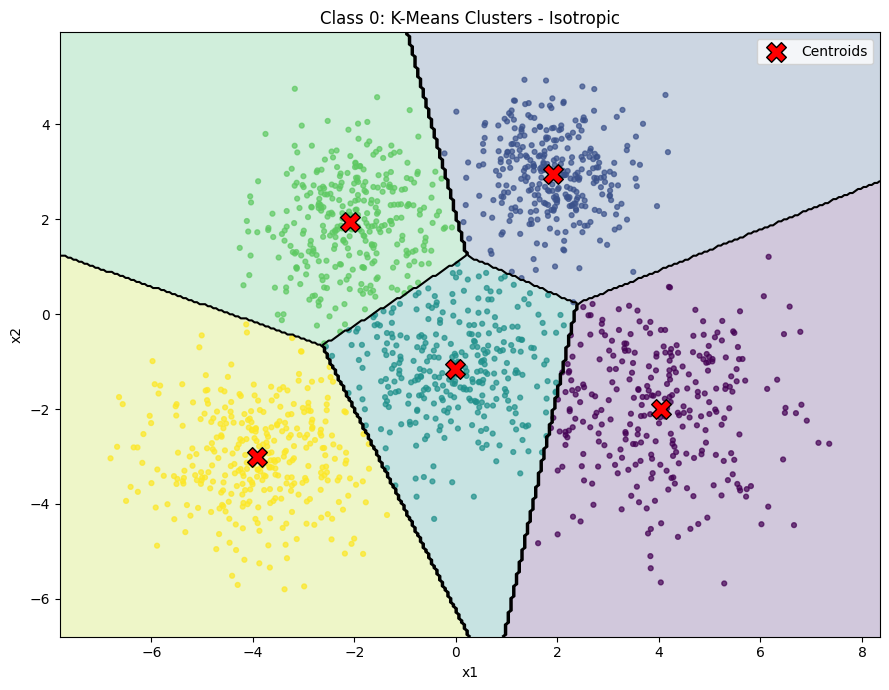

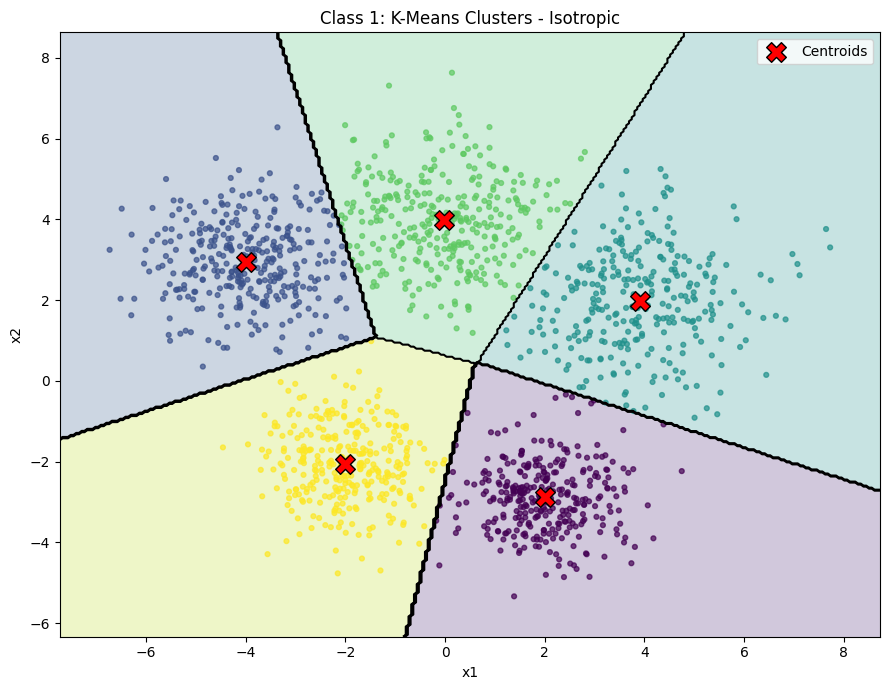


Covariance: Diagonal
Class 0 test average distortion: 2.0014
Class 1 test average distortion: 2.09
Accuracy: 80.5 %
Confusion matrix:
[[325  75]
 [ 81 319]]


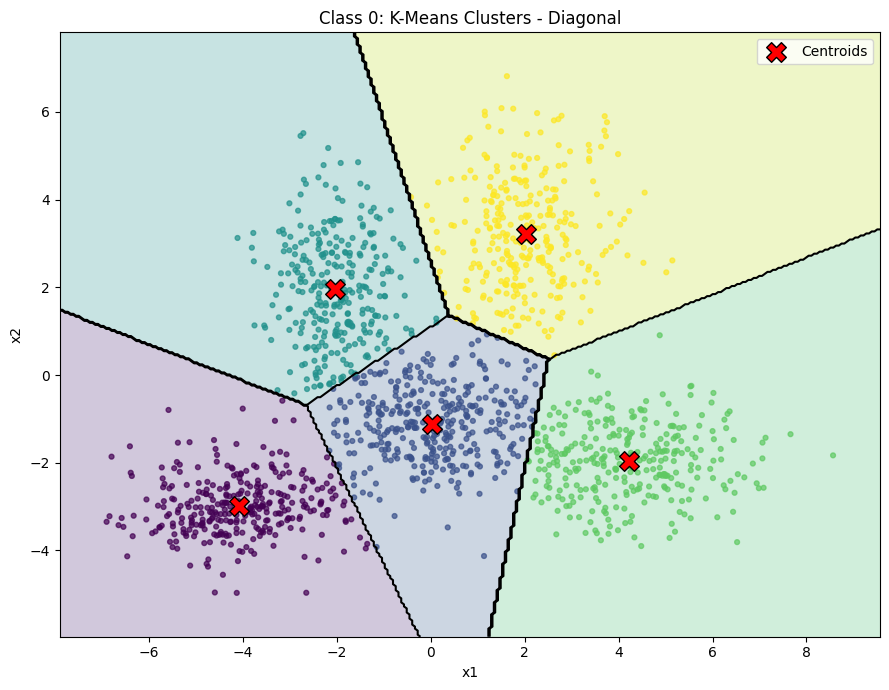

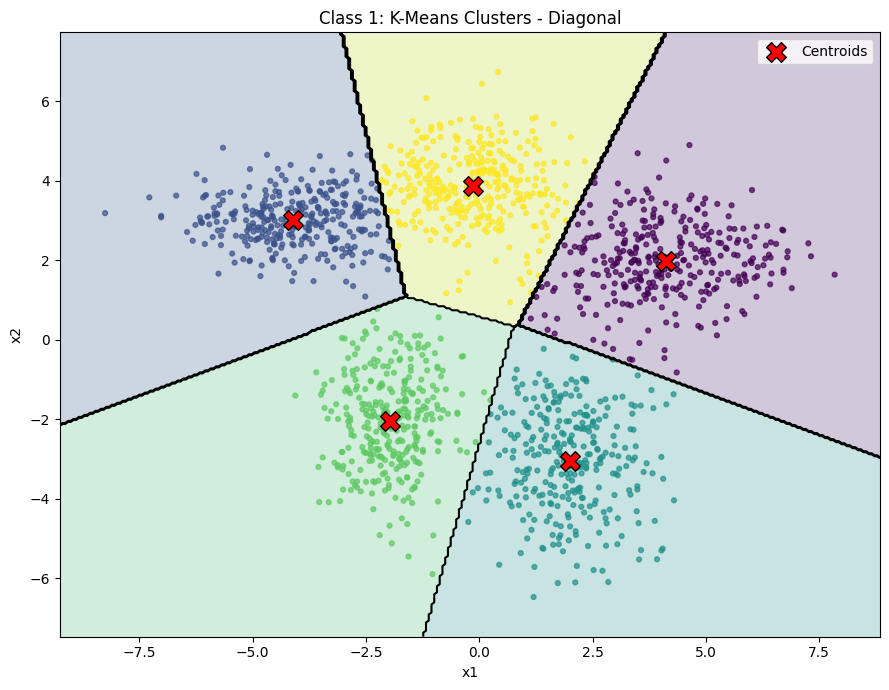


Covariance: Full
Class 0 test average distortion: 2.1861
Class 1 test average distortion: 2.094
Accuracy: 79.5 %
Confusion matrix:
[[303  97]
 [ 67 333]]


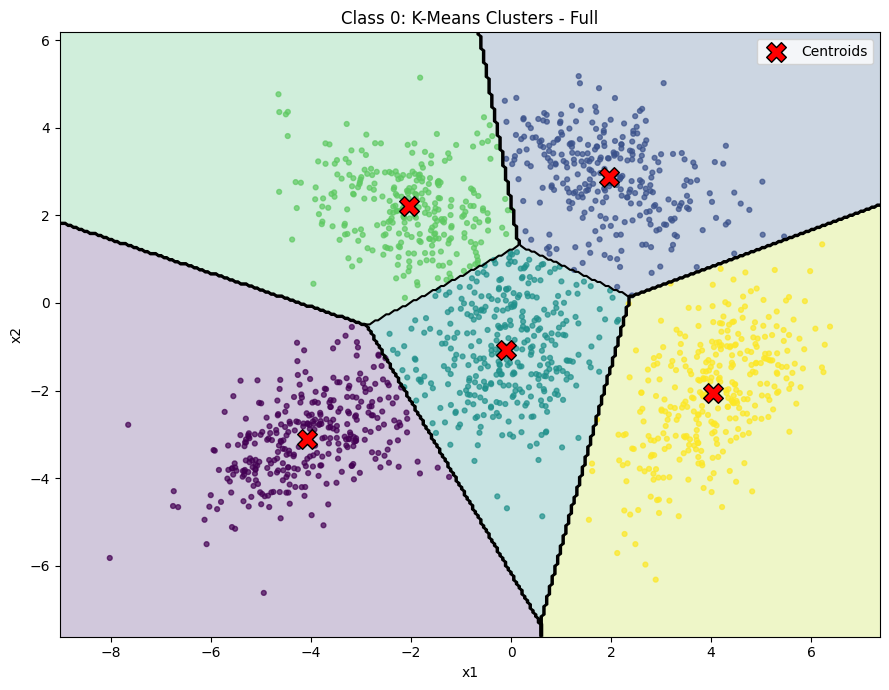

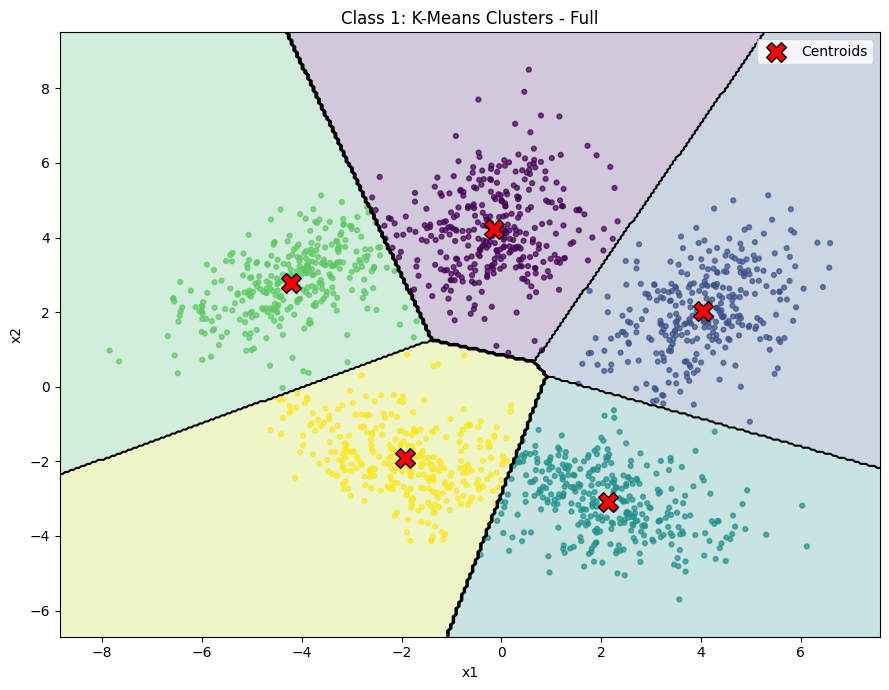

In [12]:
for covariance_name, covariances in covariance_types.items():

    X0, _ = generate_gmm_data(means_0, covariances, N)
    X1, _ = generate_gmm_data(means_1, covariances, N)

    X0_train, X0_test = train_test_split(
        X0, test_size=0.20, random_state=42
    )

    X1_train, X1_test = train_test_split(
        X1, test_size=0.20, random_state=42
    )

    centroids0, _, _ = kmeans(
        X0_train, K, random_state=42
    )

    centroids1, _, _ = kmeans(
        X1_train, K, random_state=42
    )

    X_test = np.vstack([X0_test, X1_test])

    y_test = np.concatenate([
        np.zeros(len(X0_test), dtype=int),
        np.ones(len(X1_test), dtype=int)
    ])

    def calculate_distortion(X, centroids):
        distances = np.linalg.norm(
            X[:, np.newaxis, :] - centroids[np.newaxis, :, :],
            axis=2
        )

        squared_distances = distances ** 2

        nearest_distances = np.min(squared_distances, axis=1)

        return nearest_distances

    d0 = calculate_distortion(X_test, centroids0)
    d1 = calculate_distortion(X_test, centroids1)

    y_pred = (d1 < d0).astype(int)

    accuracy = accuracy_score(y_test, y_pred)

    print("\nCovariance:", covariance_name)

    print(
        "Class 0 test average distortion:",
        round(np.mean(d0[y_test == 0]), 4)
    )

    print(
        "Class 1 test average distortion:",
        round(np.mean(d1[y_test == 1]), 4)
    )

    print("Accuracy:", round(accuracy * 100, 2), "%")

    print("Confusion matrix:")
    print(confusion_matrix(y_test, y_pred))

    plot_cluster_boundaries(
    X0_train,
    centroids0,
    f"Class 0: K-Means Clusters - {covariance_name}"
    )

    plot_cluster_boundaries(
        X1_train,
        centroids1,
        f"Class 1: K-Means Clusters - {covariance_name}"
    )


